# 1. Import Libraries

In [29]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import joblib

# splitting & Tuning
from sklearn.model_selection import train_test_split, GridSearchCV

# Feature Scaling
from sklearn.preprocessing import StandardScaler

# Linear Regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Warnings
import warnings
warnings.filterwarnings('ignore')

# 2. Load Dataset

In [22]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# 3. EDA

In [23]:
print("Shape of Data:", df.shape)

Shape of Data: (20640, 10)


In [24]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 20640
Columns: 10


In [25]:
# print all column names
print(df.columns.tolist())

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [26]:
# Data Types
print(df.dtypes)

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [28]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [10]:
# Missing Values per columns
df.isnull().sum()


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [12]:
# Duplicate Values
print(df.duplicated().sum())

0


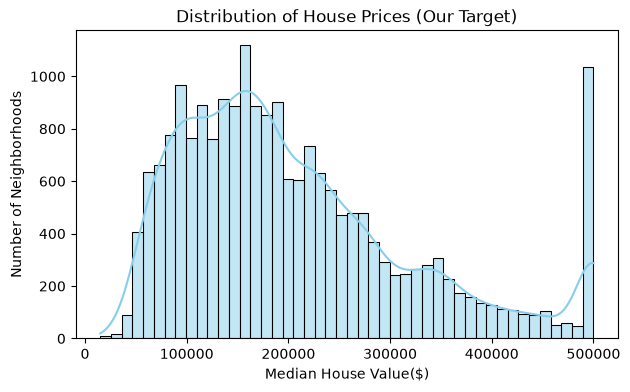

Price Summary:
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


In [13]:
plt.figure(figsize=(7,4))
sns.histplot(df["median_house_value"], kde=True, color="skyblue")
plt.title("Distribution of House Prices (Our Target)")
plt.xlabel("Median House Value($)")
plt.ylabel("Number of Neighborhoods")
plt.show()

print("Price Summary:")
print(df["median_house_value"].describe())

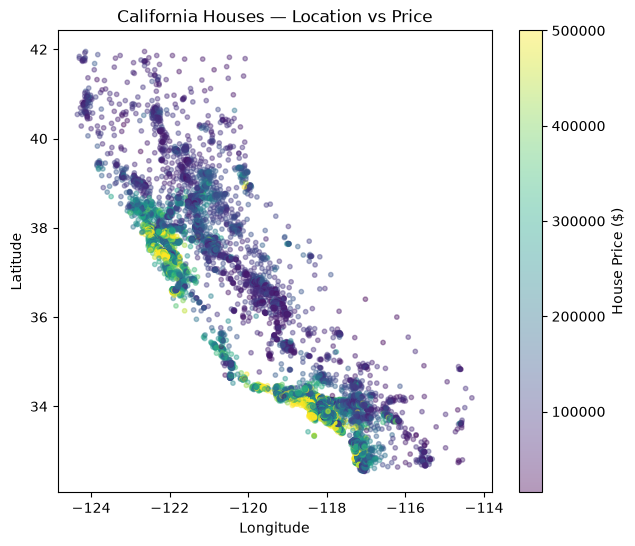

In [14]:
plt.figure(figsize=(7, 6))
plt.scatter(df["longitude"], df["latitude"],
            c=df["median_house_value"], cmap="viridis", alpha=0.4, s=10)
plt.colorbar(label="House Price ($)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Houses — Location vs Price")
plt.show()

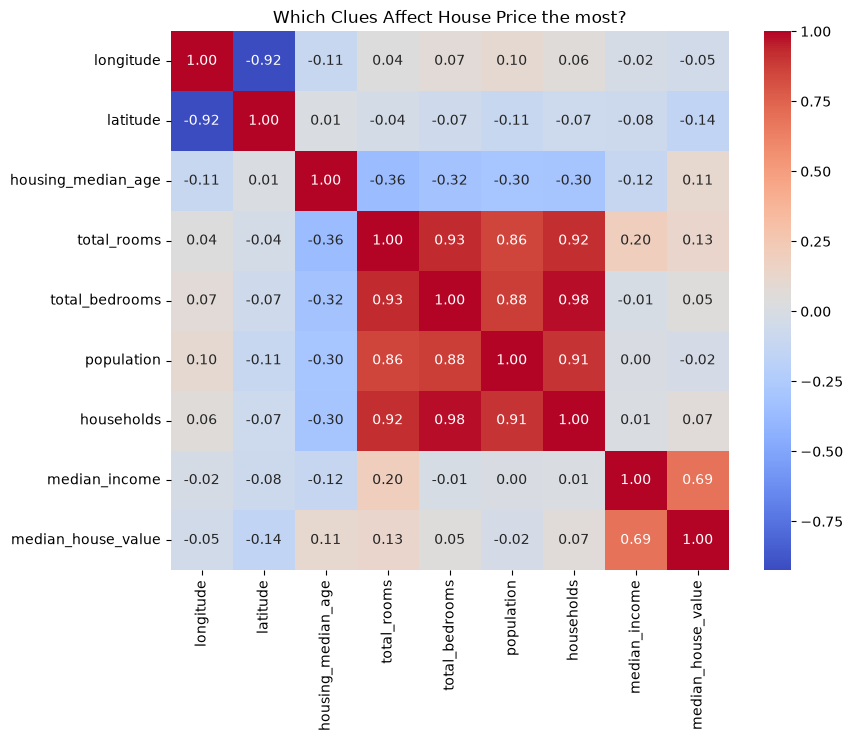

Correlation of each feature with price, sorted:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [15]:
# Correlation heatmap

plt.figure(figsize=(9,7))
numeric_data = df.select_dtypes(include=[np.number])
corr = numeric_data.corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Which Clues Affect House Price the most?")
plt.show()

print("Correlation of each feature with price, sorted:")
print(corr["median_house_value"].sort_values(ascending=False))

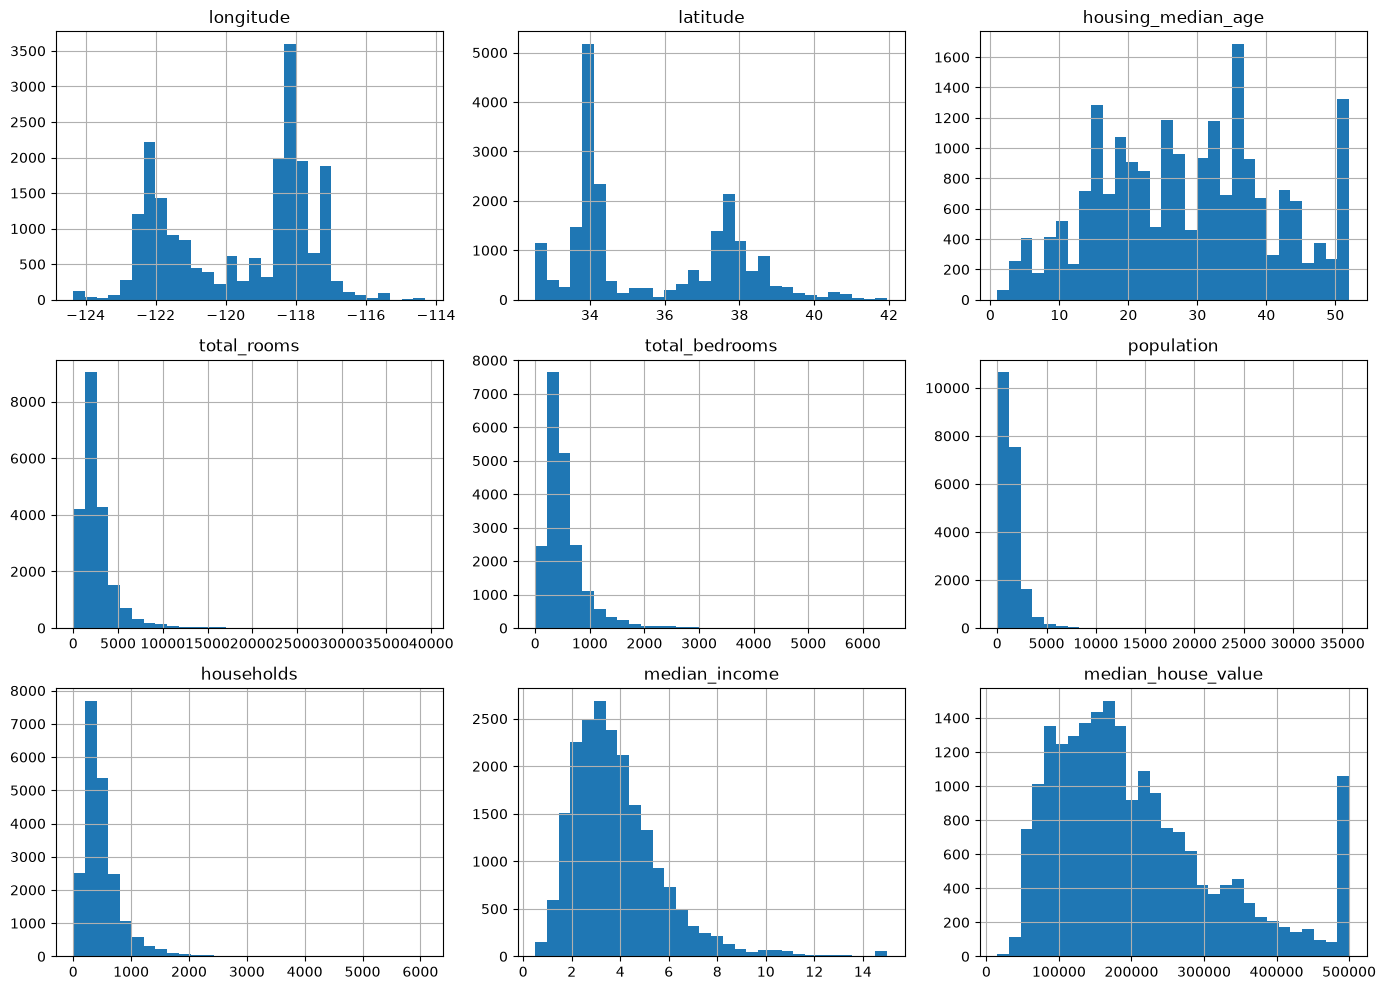

In [16]:
# Distribution of every numeric column at once — quick way to spot skewed or unusual columns
df.select_dtypes(include=[np.number]).hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

Categories in ocean_proximity: <StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str


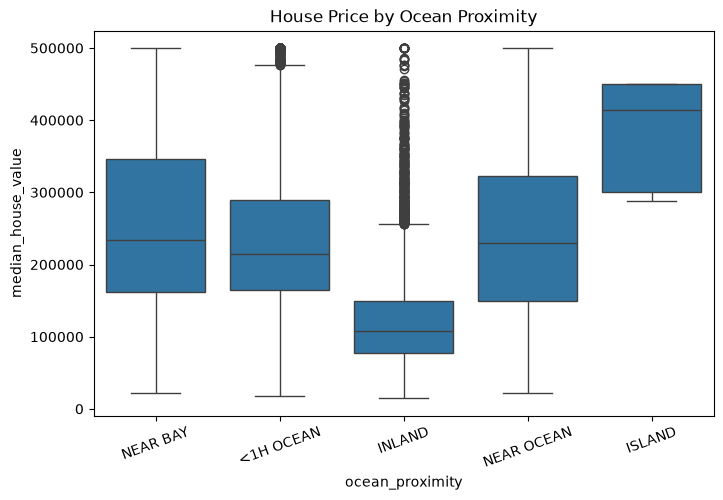

In [17]:
# What text categories exist in 'ocean_proximity'? Does location category affect price?
print("Categories in ocean_proximity:", df["ocean_proximity"].unique())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value")
plt.title("House Price by Ocean Proximity")
plt.xticks(rotation=20)
plt.show()

# 4. Data Preprocessing

In [18]:
# ----------------------------------------------------------------
# 4.1 Fix missing values: fill missing 'total_bedrooms' with the MEDIAN
# (like filling a blank exam answer with the class average — a simple, common trick)
# ----------------------------------------------------------------
median_bedrooms = df["total_bedrooms"].median()
df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)

print("Missing values in total_bedrooms after fixing:",
      df["total_bedrooms"].isnull().sum())

Missing values in total_bedrooms after fixing: 0


In [19]:
# ----------------------------------------------------------------
# 4.2 Convert the text column 'ocean_proximity' into numeric Yes/No columns
# pd.get_dummies() creates a new column for each category (1 = Yes, 0 = No)
# drop_first=True avoids redundant columns (a common best practice)
# ----------------------------------------------------------------
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True)

print("✅ ocean_proximity converted to numeric columns.")
df.head()

✅ ocean_proximity converted to numeric columns.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,True,False


In [20]:
# Double-check: no missing values and no text columns left anywhere
print("Any missing values left?", df.isnull().sum().sum())
print("\nColumn data types now:")
print(df.dtypes)

Any missing values left? 0

Column data types now:
longitude                     float64
latitude                      float64
housing_median_age            float64
total_rooms                   float64
total_bedrooms                float64
population                    float64
households                    float64
median_income                 float64
median_house_value            float64
ocean_proximity_INLAND           bool
ocean_proximity_ISLAND           bool
ocean_proximity_NEAR BAY         bool
ocean_proximity_NEAR OCEAN       bool
dtype: object


# 5. Train_Test_Split

In [ ]:
X = df.drop("median_house_value", axis=1)
y = df[""]

# 6. Feature Scaling

# 7. Model Training

# 8. Prediction

# 9. Evaluation Metrics

# 10. Hyperparameter Tuning